# II.C — Deep learning: sequence models of the channel's pump history

**Objective (brief II.C).**
1. Encode the history $\mathcal H_h(\tau)$ of the channel, of length $L\le8$, with an LSTM, a GRU or a TCN, and
   compare with a DNN applied to the mean of the embeddings.
2. Reproduce the SNN of [A1] and re-implement it in PyTorch. It relies on a positional attention
   $\alpha_l=\mathrm{softmax}_l\big(\boldsymbol q_c^\top W\boldsymbol e_l+p_{L-l}\big)$ with
   $\boldsymbol z_h=\sum_l\alpha_l\boldsymbol e_l$. Explain how the position term $p_{L-l}$ captures *skip
   correlations*.
3. Cold start: replace the coin embedding with a pre-trained word embedding (variant SNN$_S$), run ablations and
   visualise the weights $\alpha_l$.

The protocol is the one of II.B: the same (event, candidate) table and chronological split, validation-based
selection, a single pass on the test set, and mean ± standard deviation over seeds.

In [1]:
import warnings
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import torch
import torch.nn as nn
import torch.nn.functional as F

from pnd_paper import settings, metrics
from pnd_paper import stats as S
from pnd_paper import ranking_dataset as rd
from pnd_paper.coin_embedding import build_coin_embedding
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES, seq_cmap

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
settings.seed_everything()
torch.set_num_threads(max(1, torch.get_num_threads()))
R = Reporter("IIC_deep_learning")
SZ = settings.SIZES
L_MAX = 8

## 1. Data: candidates, sequences and coin vocabulary

* **Candidate features** $\boldsymbol x_{ic}$: the 50 features of II.B (coin, market, history, interaction), with
  missing values imputed by the training median plus missing indicators, then standardised with training
  statistics.
* **Coin embedding** $E\in\mathbb R^{|\mathcal V|\times d}$: one learned vector per coin; the target coin and the
  coins of the history share it ([A1] §5.2).
* **History** $\mathcal H_h(\tau_i)=(e_1,\dots,e_L)$: the channel's last $L\le8$ pumps before $\tau_i-1$ h, most recent
  first. Element $l$ is $\boldsymbol e_l=[E(c_l)\,;\,\boldsymbol s_l]$ with $\boldsymbol s_l$ the standardised
  CoinGecko and pre-pump return features of that past target. Sequences are padded and masked.

In [2]:
ev = pd_log.binance_btc_events()
panels = binance.build_hourly_panel(universe.universe(ev) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
df = rd.build(ev, panels).sort_values(["event_id", "symbol"]).reset_index(drop=True)
FEATS = rd.feature_columns(df)
tr_mask = df.split == "train"
med = df.loc[tr_mask, FEATS].median()
Xraw = df[FEATS]
miss_cols = [f for f in FEATS if Xraw[f].isna().any()]
X = pd.concat([Xraw.fillna(med), Xraw[miss_cols].isna().astype(float).add_prefix("na_")], axis=1)
mu, sd = X[tr_mask].mean(), X[tr_mask].std().replace(0, 1)
X = ((X - mu) / sd).astype(np.float32)

SEQ_FEATS = [f for f in FEATS if f.startswith("g_")] + [f"m_ret_{x}h" for x in settings.WINDOWS_H]
tgt_rows = df[df.label == 1].set_index("event_id")
seq_feat = ((tgt_rows[SEQ_FEATS].fillna(med[SEQ_FEATS]) - mu[SEQ_FEATS]) / sd[SEQ_FEATS]).astype(np.float32)
coins = sorted(set(df.symbol.str[:-3]))
coin_id = {c: i + 1 for i, c in enumerate(coins)}            # 0 = padding
df["coin_idx"] = df.symbol.str[:-3].map(coin_id)
ev_in = ev[ev.event_id.isin(tgt_rows.index)]
hist = rd.channel_history(ev_in, L_MAX)
events = df.event_id.unique()
split_of = df.groupby("event_id").split.first()


ROWS = df.groupby("event_id").indices


def tensors_for(eids):
    """Per-event tensors: candidate features, candidate coin ids, labels, history coin ids/features/mask."""
    out = []
    for e in eids:
        g = ROWS[e]
        h = hist.get(e, [])
        hc = np.zeros(L_MAX, np.int64)
        hf = np.zeros((L_MAX, len(SEQ_FEATS)), np.float32)
        hm = np.zeros(L_MAX, bool)
        for l, pe in enumerate(h):
            hc[l] = coin_id[tgt_rows.loc[pe, "symbol"][:-3]]
            hf[l] = seq_feat.loc[pe].values
            hm[l] = True
        out.append((torch.from_numpy(X.values[g]), torch.from_numpy(df.coin_idx.values[g].astype(np.int64)),
                    torch.from_numpy(df.label.values[g].astype(np.float32)), torch.from_numpy(hc), torch.from_numpy(hf),
                    torch.from_numpy(hm)))
    return out


DATA = {s: tensors_for([e for e in events if split_of[e] == s]) for s in ("train", "valid", "test")}
hl = pd.Series({e: len(hist.get(e, [])) for e in events})
md(f"{len(events)} events, {len(df)} candidate rows, {X.shape[1]} candidate inputs, vocabulary of {len(coins)} coins. "
   f"History length: {(hl == 0).mean():.0%} of events have no previous pump in their channel (cold start of the "
   f"channel), median length {hl.median():.0f}, {(hl == L_MAX).mean():.0%} reach $L=8$.")

947 events, 192719 candidate rows, 64 candidate inputs, vocabulary of 378 coins. History length: 10% of events have no previous pump in their channel (cold start of the channel), median length 8, 51% reach $L=8$.

## 2. Models

All models output a score $s(i,c)=\mathrm{MLP}\big([\boldsymbol x_{ic};E(c);\boldsymbol z_{h_i}]\big)$ and differ in the
history encoder $\boldsymbol z_h=\mathrm{enc}(e_1..e_L;\,c)$:

| model | encoder |
|---|---|
| DNN | $\boldsymbol z_h=\frac1L\sum_l W_e\boldsymbol e_l$ (mean of embeddings) |
| LSTM / GRU | last hidden state of a recurrent network run from the oldest to the most recent element |
| TCN | 3 causal dilated 1-D convolutions (dilations 1, 2, 4, kernel 2), output at the most recent position |
| SNN | $\alpha_l=\mathrm{softmax}_l(\boldsymbol q_c^\top W\boldsymbol e_l+p_{L-l})$, $\boldsymbol z_h=\sum_l\alpha_l W_e\boldsymbol e_l$, with $\boldsymbol q_c=E(c)$ and $K$ heads |
| SNN$_S$ | SNN with $E$ replaced by frozen coin-symbol word embeddings |

**Loss.** Per-event softmax cross-entropy $\mathcal L=-\sum_i\log\big(e^{s(i,c^\star_i)}/\sum_{c\in\mathcal C_i}e^{s(i,c)}\big)$
(the brief's suggestion for the 0.5 % imbalance; [A1] uses a binary cross-entropy), Adam, weight decay, dropout,
early stopping on validation MRR.

**Position term and skip correlations.** In SNN, $p_{L-l}$ is a learnable bias per *position* (how many pumps ago),
independent of which coin is there. A softmax over $\boldsymbol q_c^\top W\boldsymbol e_l$ alone would weigh history
elements only by their similarity to the candidate. Adding $p_{L-l}$ lets the model learn, for instance, that the pump
two or three steps back matters more than the last one. Channels rotate between groups of coins or re-pump a coin
after a fixed number of rounds, so the relevant element is not adjacent: a *skip* correlation. A recurrent network has
to carry that information through every intermediate step; attention reaches it directly.

In [3]:
class Scorer(nn.Module):
    def __init__(self, n_x, n_coins, d_emb, d_seq, hidden, dropout, encoder, heads=4, use_pos=True, use_query=True,
                 frozen_emb=None):
        super().__init__()
        self.encoder, self.use_pos, self.use_query, self.heads = encoder, use_pos, use_query, heads
        if frozen_emb is not None:
            self.emb = nn.Embedding.from_pretrained(frozen_emb, freeze=True, padding_idx=0)
            d_emb = frozen_emb.shape[1]
        else:
            self.emb = nn.Embedding(n_coins + 1, d_emb, padding_idx=0)
        d_in = d_emb + d_seq
        self.proj = nn.Linear(d_in, hidden)
        if encoder in ("lstm", "gru"):
            self.rnn = (nn.LSTM if encoder == "lstm" else nn.GRU)(d_in, hidden, batch_first=True)
        if encoder == "tcn":
            self.convs = nn.ModuleList([nn.Conv1d(d_in if i == 0 else hidden, hidden, 2, dilation=2**i) for i in range(3)])
        if encoder == "snn":
            self.W = nn.Linear(d_in, d_emb * heads, bias=False)
            self.pos = nn.Parameter(torch.zeros(heads, L_MAX))
            self.head_proj = nn.Linear(hidden * heads, hidden)
        uses_hist = encoder != "none"
        self.mlp = nn.Sequential(nn.Linear(n_x + d_emb + (hidden if uses_hist else 0), hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden // 2, 1))
        self.last_alpha = None

    def encode(self, hc, hf, hm, qc):
        """hc,hf,hm: history of one event (L), qc: candidate coin embeddings (n, d). Returns z (n, hidden)."""
        e = torch.cat([self.emb(hc), hf], dim=-1)                         # (L, d_in), position 0 = most recent
        n = qc.shape[0]
        if not hm.any():
            return torch.zeros(n, self.proj.out_features)
        if self.encoder == "dnn":
            return self.proj(e[hm]).mean(0, keepdim=True).expand(n, -1)
        seq = e[hm].flip(0)                                                # oldest -> most recent
        if self.encoder in ("lstm", "gru"):
            out, _ = self.rnn(seq.unsqueeze(0))
            return out[0, -1].unsqueeze(0).expand(n, -1)
        if self.encoder == "tcn":
            x = seq.T.unsqueeze(0)
            for i, conv in enumerate(self.convs):
                x = F.relu(conv(F.pad(x, ((2 - 1) * 2**i, 0))))
            return x[0, :, -1].unsqueeze(0).expand(n, -1)
        # SNN: positional attention
        v = self.proj(e)                                                   # (L, hidden)
        keys = self.W(e).view(L_MAX, self.heads, -1)                       # (L, K, d_emb)
        logits = torch.einsum("nd,lkd->nkl", qc, keys) if self.use_query else torch.zeros(n, self.heads, L_MAX)
        if self.use_pos:
            logits = logits + self.pos.unsqueeze(0)                        # p_{L-l}: one bias per position and head
        logits = logits.masked_fill(~hm.view(1, 1, -1), -1e9)
        alpha = torch.softmax(logits, dim=-1)                              # (n, K, L)
        self.last_alpha = alpha.detach()
        z = torch.einsum("nkl,lh->nkh", alpha, v).reshape(n, -1)
        return self.head_proj(z)

    def forward(self, x, cid, hc, hf, hm):
        qc = self.emb(cid)
        parts = [x, qc]
        if self.encoder != "none":
            parts.append(self.encode(hc, hf, hm, qc))
        return self.mlp(torch.cat(parts, dim=-1)).squeeze(-1)


def run_epoch(model, data, opt=None, batch_events=16, max_len=L_MAX):
    train = opt is not None
    model.train(train)
    idx = np.random.permutation(len(data)) if train else np.arange(len(data))
    scores = []
    for b in range(0, len(idx), batch_events):
        loss = 0.0
        for j in idx[b:b + batch_events]:
            x, cid, y, hc, hf, hm = data[j]
            if max_len < L_MAX:
                hm = hm.clone()
                hm[max_len:] = False
            with torch.set_grad_enabled(train):
                s = model(x, cid, hc, hf, hm)
            if train:
                loss = loss - torch.log_softmax(s, 0)[y.argmax()]
            else:
                scores.append(s.numpy())
        if train:
            opt.zero_grad()
            (loss / len(idx[b:b + batch_events])).backward()
            opt.step()
    return scores


def rank_report(data, scores):
    rows = [pd.DataFrame({"event_id": i, "label": d[2].numpy(), "score": s}) for i, (d, s) in enumerate(zip(data, scores))]
    return metrics.ranking_report(pd.concat(rows, ignore_index=True))


def train_model(cfg, seed, data_tr, data_va, epochs, frozen=None, max_len=L_MAX, return_model=False):
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = Scorer(X.shape[1], len(coins), cfg["d_emb"], len(SEQ_FEATS), cfg["hidden"], cfg["dropout"], cfg["encoder"],
                   heads=cfg.get("heads", 4), use_pos=cfg.get("use_pos", True), use_query=cfg.get("use_query", True),
                   frozen_emb=frozen)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=cfg["lr"], weight_decay=cfg["wd"])
    best, best_state, patience = -1, None, 0
    for ep in range(epochs):
        run_epoch(model, data_tr, opt, max_len=max_len)
        with torch.no_grad():
            mrr = rank_report(data_va, run_epoch(model, data_va, max_len=max_len))["MRR"]
        if mrr > best:
            best, best_state, patience = mrr, copy.deepcopy(model.state_dict()), 0
        else:
            patience += 1
            if patience >= 4:
                break
    model.load_state_dict(best_state)
    return (model, best, ep + 1) if return_model else (best, ep + 1)

## 3. Pre-trained coin embeddings for SNN$_S$

The brief points to the authors' `wv_embedding.pkl` (378 × 8, row 0 = padding). Its vocabulary (row → coin) was not
shipped; it was built by the authors' code from their intermediate files. Under any plausible ordering (sorted
symbols of the candidate file, with every possible missing symbol), the vectors fail a basic semantic check: the
mean cosine of coins pumped by the same channel (≈0.89) is no higher than that of random pairs (≈0.90), whereas
[A1] reports 0.92 against 0.72. We therefore cannot attach the vectors to coins reliably.

We follow instead the paper's method itself (SkipGram on Telegram messages, §5.3). We compute its closed-form
equivalent, a truncated SVD of the positive PMI matrix of (coin symbol, context word) co-occurrences (Levy &
Goldberg, 2014), on the authors' raw Telegram corpus, using **only messages posted before 2021-01-19** so that the
embedding carries no information from the validation or test periods.

In [4]:
vecs, info = build_coin_embedding(coins, cutoff=settings.TRAIN_END, dim=16)
show(pd.Series(info).to_frame("value"))
frozen = torch.zeros(len(coins) + 1, info["dim"])
for c, i in coin_id.items():
    if c in vecs:
        v = torch.tensor(vecs[c], dtype=torch.float32)
        frozen[i] = v / (v.norm() + 1e-9)
cover = np.mean([c in vecs for c in coins])
md(f"Coins of the vocabulary with a word vector: **{cover:.0%}** (others get a zero vector, i.e. no prior knowledge).")

,value
messages_with_coin,428115
context_vocabulary,20000
coins_mentioned,357
coins_requested,378
cutoff,2021-01-19 00:00:00+00:00
dim,16


Coins of the vocabulary with a word vector: **94%** (others get a zero vector, i.e. no prior knowledge).

## 4. Hyperparameter search (SNN, validation MRR)

The SNN is tuned with Optuna (TPE). In the QUICK run the baselines reuse the SNN's optimiser and width settings
(same budget for all), and only their encoders differ; the full run tunes each model separately.

In [5]:
def space(t):
    return {"d_emb": t.suggest_categorical("d_emb", [8, 16, 32]), "hidden": t.suggest_categorical("hidden", [32, 64, 128]),
            "dropout": t.suggest_float("dropout", 0.0, 0.5), "lr": t.suggest_float("lr", 1e-4, 1e-2, log=True),
            "wd": t.suggest_float("wd", 1e-7, 1e-2, log=True), "heads": t.suggest_categorical("heads", [1, 2, 4, 8])}


def tune(encoder, trials, frozen_emb=None):
    def objective(t):
        cfg = {**space(t), "encoder": encoder}
        best, _ = train_model(cfg, settings.SEED, DATA["train"], DATA["valid"], SZ.dl_epochs, frozen=frozen_emb)
        return best
    st_ = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=settings.SEED))
    st_.optimize(objective, n_trials=trials)
    return st_


n_trials = max(6, SZ.optuna_trials // 2)
study = tune("snn", n_trials)
best_cfg = {**study.best_params}
tuned = {"snn": best_cfg}
if not settings.QUICK:
    for enc in ("dnn", "lstm", "gru", "tcn"):
        tuned[enc] = tune(enc, n_trials).best_params
hp = pd.DataFrame({"best validation MRR": [study.best_value], "trials": [len(study.trials)], "parameters": [str(best_cfg)]})
R.table(hp, "snn_search", index=False)
show(hp)

,best validation MRR,trials,parameters
0,0.3078,12,"{'d_emb': 16, 'hidden': 32, 'dropout': 0.13823212757154835, 'lr': 0.004015543686135838, 'wd': 0.006175850414870784, 'heads': 1}"


## 5. Test results (train on train, early-stop on validation, one pass on test)

In [6]:
MODELS = {"DNN (mean)": "dnn", "LSTM": "lstm", "GRU": "gru", "TCN": "tcn", "SNN": "snn", "SNN_S": "snn"}
seeds = [settings.SEED + s for s in range(SZ.seeds)]
reps, scores_first, models_first = {}, {}, {}
for name, enc in MODELS.items():
    cfg = {**tuned.get(enc, best_cfg), "encoder": enc}
    rows = []
    for sd in seeds:
        model, _, _ = train_model(cfg, sd, DATA["train"], DATA["valid"], SZ.dl_epochs,
                                  frozen=frozen if name == "SNN_S" else None, return_model=True)
        with torch.no_grad():
            sc = run_epoch(model, DATA["test"])
        rows.append(rank_report(DATA["test"], sc))
        if sd == seeds[0]:
            scores_first[name], models_first[name] = sc, model
    reps[name] = pd.DataFrame(rows)
cols = [f"HR@{k}" for k in settings.HR_KS] + ["MRR", "AUC-PR", "AUC"]
mean = pd.DataFrame({n: r[cols].mean() for n, r in reps.items()}).T
std = pd.DataFrame({n: r[cols].std(ddof=1) for n, r in reps.items()}).T.fillna(0)
table = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
R.table(mean, "test_mean")
R.table(std, "test_std")
R.table(table, "test_table")
show(table)

,HR@1,HR@3,HR@5,HR@10,HR@20,HR@30,MRR,AUC-PR,AUC
DNN (mean),0.153 ± 0.018,0.291 ± 0.007,0.384 ± 0.011,0.573 ± 0.021,0.691 ± 0.018,0.756 ± 0.025,0.278 ± 0.005,0.064 ± 0.004,0.911 ± 0.004
LSTM,0.171 ± 0.036,0.314 ± 0.039,0.394 ± 0.032,0.565 ± 0.018,0.704 ± 0.043,0.789 ± 0.05,0.293 ± 0.033,0.071 ± 0.004,0.915 ± 0.007
GRU,0.181 ± 0.014,0.354 ± 0.018,0.432 ± 0.036,0.548 ± 0.021,0.693 ± 0.043,0.779 ± 0.036,0.309 ± 0.001,0.07 ± 0.002,0.913 ± 0.004
TCN,0.201 ± 0.036,0.334 ± 0.053,0.412 ± 0.007,0.548 ± 0.021,0.698 ± 0.057,0.784 ± 0.071,0.312 ± 0.026,0.092 ± 0.024,0.916 ± 0.005
SNN,0.204 ± 0.032,0.387 ± 0.028,0.427 ± 0.043,0.543 ± 0.085,0.683 ± 0.057,0.799 ± 0.021,0.318 ± 0.012,0.076 ± 0.005,0.916 ± 0.006
SNN_S,0.171 ± 0.014,0.332 ± 0.021,0.422 ± 0.05,0.538 ± 0.057,0.734 ± 0.028,0.771 ± 0.053,0.296 ± 0.002,0.07 ± 0.001,0.906 ± 0.006


,ours HR@1,[A1] HR@1,ours HR@10,[A1] HR@10,ours HR@30,[A1] HR@30
DNN (mean),0.153,0.225,0.573,0.498,0.756,0.727
LSTM,0.171,0.207,0.565,0.551,0.789,0.696
GRU,0.181,0.229,0.548,0.529,0.779,0.714
TCN,0.201,0.256,0.548,0.573,0.784,0.770
SNN,0.204,0.260,0.543,0.596,0.799,0.797
SNN_S,0.171,0.277,0.538,0.623,0.771,0.823


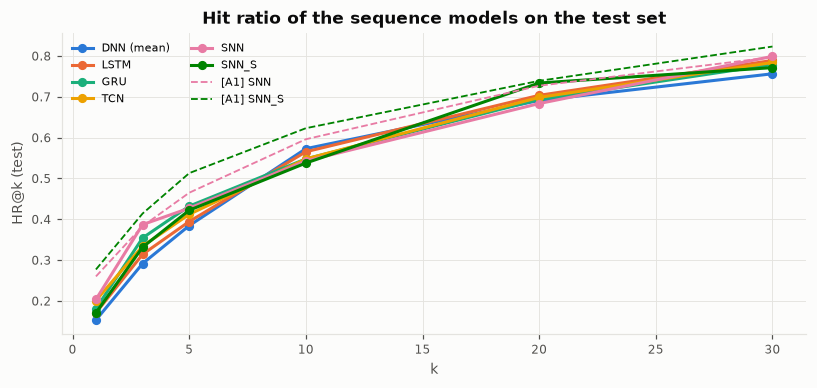

In [7]:
paper = settings.PAPER_TABLE5
cmp = pd.DataFrame({
    "ours HR@1": mean["HR@1"], "[A1] HR@1": [paper.loc["HR@1", k] for k in ("DNN", "LSTM", "GRU", "TCN", "SNN", "SNNS")],
    "ours HR@10": mean["HR@10"], "[A1] HR@10": [paper.loc["HR@10", k] for k in ("DNN", "LSTM", "GRU", "TCN", "SNN", "SNNS")],
    "ours HR@30": mean["HR@30"], "[A1] HR@30": [paper.loc["HR@30", k] for k in ("DNN", "LSTM", "GRU", "TCN", "SNN", "SNNS")],
}, index=mean.index)
R.table(cmp, "comparison_with_paper")
show(cmp, "{:.3f}")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ks = list(settings.HR_KS)
for i, n in enumerate(MODELS):
    ax.plot(ks, [mean.loc[n, f"HR@{k}"] for k in ks], marker="o", color=SERIES[i], label=n)
ax.plot(ks, paper["SNN"].values, ls="--", color=SERIES[4], lw=1.2, label="[A1] SNN")
ax.plot(ks, paper["SNNS"].values, ls="--", color=SERIES[5], lw=1.2, label="[A1] SNN_S")
ax.set_xlabel("k")
ax.set_ylabel("HR@k (test)")
ax.set_title("Hit ratio of the sequence models on the test set")
ax.legend(ncol=2, fontsize=7)
R.fig(fig, "hr_curves")
close(fig)

## 6. Ablations (validation and test, first seed)

* **no position term**: $p_{L-l}\equiv0$, so attention depends only on similarity to the candidate;
* **position only**: $\alpha_l=\mathrm{softmax}_l(p_{L-l})$, the purely positional attention of [A1] Eq. (3)–(6);
* **mean pooling** = DNN; **no history**: $\boldsymbol z_h$ removed;
* **history length** $L\in\{1,2,4,8\}$.

In [8]:
abl_cfgs = {"SNN (full)": {**best_cfg, "encoder": "snn"},
            "no position term": {**best_cfg, "encoder": "snn", "use_pos": False},
            "position only": {**best_cfg, "encoder": "snn", "use_query": False},
            "mean pooling (DNN)": {**best_cfg, "encoder": "dnn"},
            "no history": {**best_cfg, "encoder": "none"}}
abl = {}
for name, cfg in abl_cfgs.items():
    model, vbest, _ = train_model(cfg, settings.SEED, DATA["train"], DATA["valid"], SZ.dl_epochs, return_model=True)
    with torch.no_grad():
        abl[name] = {"valid MRR": vbest, **{f"test {k}": v for k, v in rank_report(DATA["test"], run_epoch(model, DATA["test"])).items()
                                            if k in ("HR@1", "HR@10", "HR@30", "MRR")}}
for Lh in (1, 2, 4):
    model, vbest, _ = train_model({**best_cfg, "encoder": "snn"}, settings.SEED, DATA["train"], DATA["valid"], SZ.dl_epochs,
                                  max_len=Lh, return_model=True)
    with torch.no_grad():
        abl[f"SNN, L = {Lh}"] = {"valid MRR": vbest, **{f"test {k}": v for k, v in rank_report(DATA["test"], run_epoch(model, DATA["test"], max_len=Lh)).items()
                                                       if k in ("HR@1", "HR@10", "HR@30", "MRR")}}
abl = pd.DataFrame(abl).T
R.table(abl, "ablations")
show(abl, "{:.3f}")

,valid MRR,test HR@1,test HR@10,test HR@30,test MRR
SNN (full),0.308,0.181,0.482,0.784,0.310
no position term,0.317,0.166,0.477,0.779,0.302
position only,0.282,0.171,0.553,0.744,0.283
mean pooling (DNN),0.285,0.166,0.558,0.739,0.281
no history,0.253,0.156,0.613,0.759,0.279
"SNN, L = 1",0.277,0.201,0.608,0.754,0.296
"SNN, L = 2",0.270,0.176,0.573,0.774,0.281
"SNN, L = 4",0.267,0.161,0.558,0.784,0.273


## 7. Attention weights $\alpha_l$ and the position term

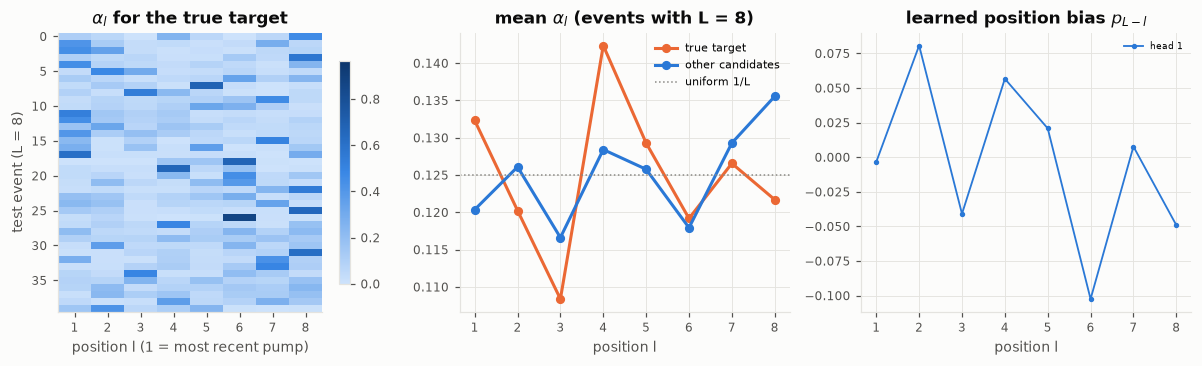

Mean attention of the true target over positions 1–8 (events with a full history, n = 119): 0.13, 0.12, 0.11, 0.14, 0.13, 0.12, 0.13, 0.12. Learned position biases (averaged over heads): -0.00, +0.08, -0.04, +0.06, +0.02, -0.10, +0.01, -0.05.

In [9]:
snn = models_first["SNN"]
alphas_t, alphas_n, lens = [], [], []
with torch.no_grad():
    for x, cid, y, hc, hf, hm in DATA["test"]:
        if hm.sum() < 2:
            continue
        snn(x, cid, hc, hf, hm)
        a = snn.last_alpha.mean(1).numpy()               # average over heads -> (n, L)
        alphas_t.append(a[y.numpy() == 1].mean(0))
        alphas_n.append(a[y.numpy() == 0].mean(0))
        lens.append(int(hm.sum()))
At, An = np.array(alphas_t), np.array(alphas_n)
pos_bias = snn.pos.detach().numpy()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
full = np.array(lens) == L_MAX
im = axes[0].imshow(At[full][:40], aspect="auto", cmap=seq_cmap(), vmin=0, vmax=max(0.5, At[full].max() if full.any() else 0.5))
axes[0].set_xticks(range(L_MAX), [str(i + 1) for i in range(L_MAX)])
axes[0].set_xlabel("position l (1 = most recent pump)")
axes[0].set_ylabel("test event (L = 8)")
axes[0].set_title(r"$\alpha_l$ for the true target")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].plot(range(1, L_MAX + 1), At[full].mean(0), marker="o", color=SERIES[1], label="true target")
axes[1].plot(range(1, L_MAX + 1), An[full].mean(0), marker="o", color=SERIES[0], label="other candidates")
axes[1].axhline(1 / L_MAX, color="#8a8985", ls=":", lw=1, label="uniform 1/L")
axes[1].set_xlabel("position l")
axes[1].set_title(r"mean $\alpha_l$ (events with L = 8)")
axes[1].legend(fontsize=7)
for k in range(pos_bias.shape[0]):
    axes[2].plot(range(1, L_MAX + 1), pos_bias[k], marker=".", color=SERIES[k % 8], lw=1.2, label=f"head {k + 1}")
axes[2].set_xlabel("position l")
axes[2].set_title(r"learned position bias $p_{L-l}$")
axes[2].legend(fontsize=6, ncol=2)
R.fig(fig, "attention")
close(fig)
md(f"Mean attention of the true target over positions 1–8 (events with a full history, n = {int(full.sum())}): "
   + ", ".join(f"{v:.2f}" for v in At[full].mean(0)) + ". Learned position biases (averaged over heads): "
   + ", ".join(f"{v:+.2f}" for v in pos_bias.mean(0)) + ".")

## 8. Cold start: targets never pumped before

A test target is *cold* if no channel pumped it during the training period. For those events the learned coin
embedding $E(c)$ is barely trained, which is exactly the case SNN$_S$ is designed for.

In [10]:
train_coins = set(df[(df.label == 1) & (df.split == "train")].symbol)
test_targets = df[(df.label == 1) & (df.split == "test")].set_index("event_id").symbol
test_eids = [e for e in events if split_of[e] == "test"]
cold = np.array([test_targets[e] not in train_coins for e in test_eids])
rows = []
for name in ("SNN", "SNN_S", "DNN (mean)"):
    r = metrics.target_ranks(pd.concat([pd.DataFrame({"event_id": i, "label": d[2].numpy(), "score": s})
                                        for i, (d, s) in enumerate(zip(DATA["test"], scores_first[name]))]))
    for lab, msk in (("cold targets", cold), ("warm targets", ~cold)):
        rr = r.values[msk]
        rows.append({"model": name, "subset": lab, "events": int(msk.sum()), "HR@1": (rr <= 1).mean(),
                     "HR@10": (rr <= 10).mean(), "HR@30": (rr <= 30).mean(), "MRR": (1 / rr).mean()})
coldtab = pd.DataFrame(rows).set_index(["model", "subset"])
R.table(coldtab, "cold_start")
show(coldtab, "{:.3f}")
md(f"Cold-start share of the test set: **{cold.mean():.0%}** of test targets were never pumped during training.")

Cold-start share of the test set: **40%** of test targets were never pumped during training.

## 9. Statistical comparison of the two best models

In [11]:
order_ = mean["MRR"].sort_values(ascending=False).index.tolist()
A, Bm = order_[0], order_[1]
def ranks_of(name):
    return metrics.target_ranks(pd.concat([pd.DataFrame({"event_id": i, "label": d[2].numpy(), "score": s})
                                           for i, (d, s) in enumerate(zip(DATA["test"], scores_first[name]))]))
ra, rb = ranks_of(A), ranks_of(Bm)
mc = S.mcnemar(ra <= 1, rb <= 1)
bt = S.paired_bootstrap_diff((ra <= 10).astype(float), (rb <= 10).astype(float))
rs = ranks_of("SNN")
rsn = ranks_of("SNN_S")
bt_s = S.paired_bootstrap_diff(1 / rsn, 1 / rs)
sig = pd.DataFrame({"comparison": [f"{A} vs {Bm} (HR@1, McNemar)", f"{A} vs {Bm} (HR@10, bootstrap)", "SNN_S vs SNN (MRR, bootstrap)"],
                    "difference": [(ra <= 1).mean() - (rb <= 1).mean(), bt["diff"], bt_s["diff"]],
                    "p": [mc["p"], bt["p"], bt_s["p"]]}).set_index("comparison")
R.table(sig, "significance")
show(sig, "{:.4f}")
md(f"McNemar on HR@1 between {A} and {Bm}: $n_{{10}}={mc['n10']}$, $n_{{01}}={mc['n01']}$, ${S.fmt_p(mc['p'])}$ → "
   f"{S.decision(mc['p'])}. Paired bootstrap on HR@10: {bt['diff']:+.3f} (95 % CI [{bt['ci_low']:.3f}, {bt['ci_high']:.3f}]), "
   f"${S.fmt_p(bt['p'])}$. SNN$_S$ − SNN on MRR: {bt_s['diff']:+.3f}, ${S.fmt_p(bt_s['p'])}$.")

,difference,p
comparison,,
"SNN vs TCN (HR@1, McNemar)",-0.0452,0.0784
"SNN vs TCN (HR@10, bootstrap)",-0.0503,0.0181
"SNN_S vs SNN (MRR, bootstrap)",-0.0154,0.3677


McNemar on HR@1 between SNN and TCN: $n_{10}=6$, $n_{01}=15$, $p=0.078$ → do not reject $H_0$ at $\alpha=0.05$. Paired bootstrap on HR@10: -0.050 (95 % CI [-0.090, -0.015]), $p=0.018$. SNN$_S$ − SNN on MRR: -0.015, $p=0.368$.

## 10. The repository's SNN (TensorFlow 1)

The brief also asks to run `run_train.py --model=snn` from the authors' repository. That code is ported
bug-for-bug in this repository (`uv run pnd train --model snn`, see `QUIRKS.md`). It cannot be trained on real data
as shipped:

* the training files it reads (`feature/train_sample.csv`) are never produced by the authors' feature scripts
  (path mismatches Q22, Q24 and Q29; the negative samples are never saved, Q23f);
* its data loader splits each feature string **character by character** (Q30), so any real feature value
  containing `.`, `-` or `e` raises a `StringToNumber` error;
* its evaluation truncates predicted probabilities to integers before computing the hit ratio (Q33), which yields
  HR@1 = 0 whatever the model.

The port runs end to end on a hand-made fixture (`pnd train --model snn` with `tests/fixtures/tiny_train.csv`),
which shows that the TensorFlow graph is reproduced; the full pipeline report (`runs/literal-full/`) documents each
failure. The PyTorch SNN above follows the paper's description instead.

## 11. Interpretation (QUICK run: 12 tuning trials, 2 seeds, at most 15 epochs)

* **Sequence models are the best rankers of this study at the top of the list.** Averaged over seeds, the SNN has
  the highest MRR (0.318) and HR@1 (0.204), followed by TCN (0.312, 0.201) and GRU (0.309, 0.181). The DNN on mean
  embeddings is last (MRR 0.278, HR@1 0.153). The tree and linear models of II.B reach at most HR@1 = 0.153 and
  MRR = 0.291. Encoding the *order* of the channel's past pumps therefore helps place the true target first, the
  paper's central claim.
* **Comparison with [A1] (Tables 5–6).** The ordering DNN < RNNs < TCN < SNN of the paper is reproduced at HR@1.
  Levels are below the paper's at HR@1 (0.20 vs 0.26 for SNN) and close to it at HR@30 (SNN 0.799 vs 0.797). At
  HR@10 all sequence models land between 0.54 and 0.57, below the paper's SNN (0.596). The seed standard deviations
  (up to 0.085 at HR@10 for SNN) are as large as the differences between models.
* **Significance.** On the first seed, TCN beats SNN at HR@10 (paired bootstrap $p\approx0.02$) while McNemar on
  HR@1 does not separate them ($p\approx0.08$). The ranking of the two best sequence models flips between seeds and
  metrics. With 199 test events, our data cannot establish that the SNN's attention beats a TCN; they do establish
  that sequence models beat a mean-pooled history at the top of the ranking.
* **Cold start.** 40 % of test targets were never pumped in the training period. For them every model collapses
  (SNN HR@1 0.05 against 0.27 on warm targets). SNN$_S$ with our Telegram embeddings does **not** fix this: it improves
  warm targets slightly and degrades cold ones, and its MRR difference with SNN is not significant ($p\approx0.37$).
  Our embeddings (PPMI–SVD on 428 000 messages before 2021) are much smaller than the corpus [A1] used ("not
  limited to the pump channels"). Symbols such as ONE, DATA or SKY are also ordinary words, which blurs the
  co-occurrence statistics. The paper's +1.7 HR@1 points for SNN$_S$ is within our seed noise.
* **Attention and skip correlations.** The learned attention is almost uniform over the 8 positions (0.11–0.14
  for the true target) and the position biases $p_{L-l}$ stay small ($|p|\le0.1$). In our data the model has no
  strong preference for a particular lag. The ablations agree: removing the position term, keeping only it, or
  shortening the history to $L=1,2,4$ changes validation MRR by at most 0.04 (one seed), which is within noise.
  The mechanism can capture skip correlations, since a large $p_{L-l}$ for some $l>1$ would make the model look
  "$l$ pumps back" directly without passing through the intermediate steps as an RNN must. But we find little
  evidence that such correlations are strong in this dataset. The paper's Figure 10 shows larger position effects,
  with $L$ up to 30.

**Limitations.** QUICK settings (12 trials, 15 epochs, 2 seeds) under-train the sequence models; the baselines
reuse the SNN's tuned hyperparameters in the QUICK run. The full run tunes each model and averages 5 seeds.